# 04 · Model Training, Tuning & Evaluation

Two prediction questions are answered with the same rigorous protocol:

| | Features | Children | Question |
|---|---|---|---|
| **Set A** | demographics + IQ (+ engineered) | all 935 | *Can ADHD be predicted without a symptom questionnaire?* |
| **Set B** | Set A + parent symptom ratings | 477 (NYU + Peking) | *How well does a realistic screening model perform?* |

Protocol
1. Baseline (majority class)
2. Compare **13 algorithms** with 5-fold stratified CV on the training set
3. Hyper-parameter tuning (`RandomizedSearchCV`) of the strongest models
4. Ensembles (soft voting & stacking)
5. Decision-threshold selection on out-of-fold predictions
6. **One-time evaluation on the locked test set**, with bootstrap confidence intervals
7. Robustness: leave-one-site-out, the site confound, subgroup (sex) performance
8. Secondary task: ADHD subtype classification
9. Save models and metrics

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import VotingClassifier, StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (StratifiedKFold, cross_validate, cross_val_predict,
                                     RandomizedSearchCV, LeaveOneGroupOut)
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, balanced_accuracy_score, f1_score, recall_score, precision_score,
                             accuracy_score, confusion_matrix, roc_curve, precision_recall_curve,
                             average_precision_score, brier_score_loss, classification_report)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.svm import SVC

from neuroadhd.config import DATA_PROCESSED, MODELS, REPORTS, WEBSITE_DATA, RANDOM_STATE
from neuroadhd.features import FEATURE_SETS, make_preprocessor, model_zoo
from neuroadhd.plotting import (savefig, PALETTE, TD_COLOR, ADHD_COLOR, SEQ_BLUE, INK, INK_2, MUTED, SURFACE, GRID)

df = pd.read_csv(DATA_PROCESSED / "adhd200_model_ready.csv")
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"roc_auc": "roc_auc", "balanced_accuracy": "balanced_accuracy", "f1": "f1",
           "recall": "recall", "precision": "precision", "accuracy": "accuracy"}

def get_xy(set_name, split):
    fs = FEATURE_SETS[set_name]
    d = df[df.split == split]
    if set_name.startswith("B"):
        d = d[d.rating_scale.notna()]
    return d, d[fs["numeric"] + fs["categorical"]], d["adhd"].values

def pipe_for(set_name, clf):
    fs = FEATURE_SETS[set_name]
    return Pipeline([("prep", make_preprocessor(fs["numeric"], fs["categorical"], "median")), ("clf", clf)])

for s in FEATURE_SETS:
    d, X, y = get_xy(s, "train"); dt, Xt, yt = get_xy(s, "test")
    print(f"{s:<26} train {len(y)} ({y.mean():.0%} ADHD) | test {len(yt)} ({yt.mean():.0%} ADHD) | {X.shape[1]} features")

A_demographic_cognitive    train 748 (38% ADHD) | test 187 (39% ADHD) | 9 features
B_with_symptom_ratings     train 379 (51% ADHD) | test 98 (51% ADHD) | 13 features


## 1–2. Baseline and 13-model comparison (5-fold CV on training data)

In [2]:
cv_rows = []
for set_name in FEATURE_SETS:
    _, X, y = get_xy(set_name, "train")
    zoo = {"Baseline (majority)": DummyClassifier(strategy="most_frequent"),
           **model_zoo(scale_pos_weight=(y == 0).sum() / (y == 1).sum())}
    for name, clf in zoo.items():
        t0 = time.time()
        res = cross_validate(pipe_for(set_name, clf), X, y, cv=CV, scoring=SCORING, n_jobs=-1)
        row = {"set": set_name, "model": name, "fit_s": time.time() - t0}
        for m in SCORING:
            row[m] = res[f"test_{m}"].mean(); row[f"{m}_sd"] = res[f"test_{m}"].std()
        cv_rows.append(row)
cv_df = pd.DataFrame(cv_rows)
for s in FEATURE_SETS:
    print(f"\n=== {s} ===")
    display(cv_df[cv_df.set == s].sort_values("roc_auc", ascending=False)
            [["model", "roc_auc", "roc_auc_sd", "balanced_accuracy", "f1", "recall", "precision", "accuracy"]].round(3).reset_index(drop=True))


=== A_demographic_cognitive ===


,model,roc_auc,roc_auc_sd,balanced_accuracy,f1,recall,precision,accuracy
0,Logistic Regression,0.735,0.041,0.666,0.606,0.669,0.556,0.666
1,LDA,0.735,0.041,0.655,0.554,0.495,0.634,0.693
2,Extra Trees,0.733,0.041,0.677,0.611,0.648,0.580,0.683
3,AdaBoost,0.727,0.034,0.646,0.528,0.449,0.641,0.691
4,SVM (RBF),0.721,0.044,0.646,0.585,0.648,0.534,0.646
5,Random Forest,0.714,0.040,0.663,0.588,0.592,0.586,0.679
6,Gradient Boosting,0.707,0.033,0.616,0.498,0.449,0.564,0.655
7,Gaussian NB,0.707,0.043,0.657,0.575,0.575,0.579,0.676
8,KNN,0.703,0.051,0.628,0.520,0.474,0.579,0.664
9,XGBoost,0.701,0.034,0.646,0.574,0.606,0.545,0.655



=== B_with_symptom_ratings ===


,model,roc_auc,roc_auc_sd,balanced_accuracy,f1,recall,precision,accuracy
0,Extra Trees,0.986,0.009,0.944,0.946,0.948,0.945,0.945
1,AdaBoost,0.984,0.010,0.926,0.928,0.933,0.926,0.926
2,Logistic Regression,0.984,0.009,0.932,0.932,0.923,0.944,0.931
3,LDA,0.982,0.006,0.929,0.929,0.917,0.943,0.929
4,XGBoost,0.982,0.012,0.934,0.935,0.938,0.934,0.934
5,Random Forest,0.981,0.011,0.934,0.935,0.938,0.934,0.934
6,Gradient Boosting,0.981,0.012,0.921,0.921,0.917,0.927,0.921
7,LightGBM,0.979,0.011,0.936,0.938,0.943,0.934,0.937
8,SVM (RBF),0.974,0.012,0.927,0.926,0.907,0.947,0.926
9,KNN,0.969,0.007,0.911,0.910,0.891,0.930,0.910


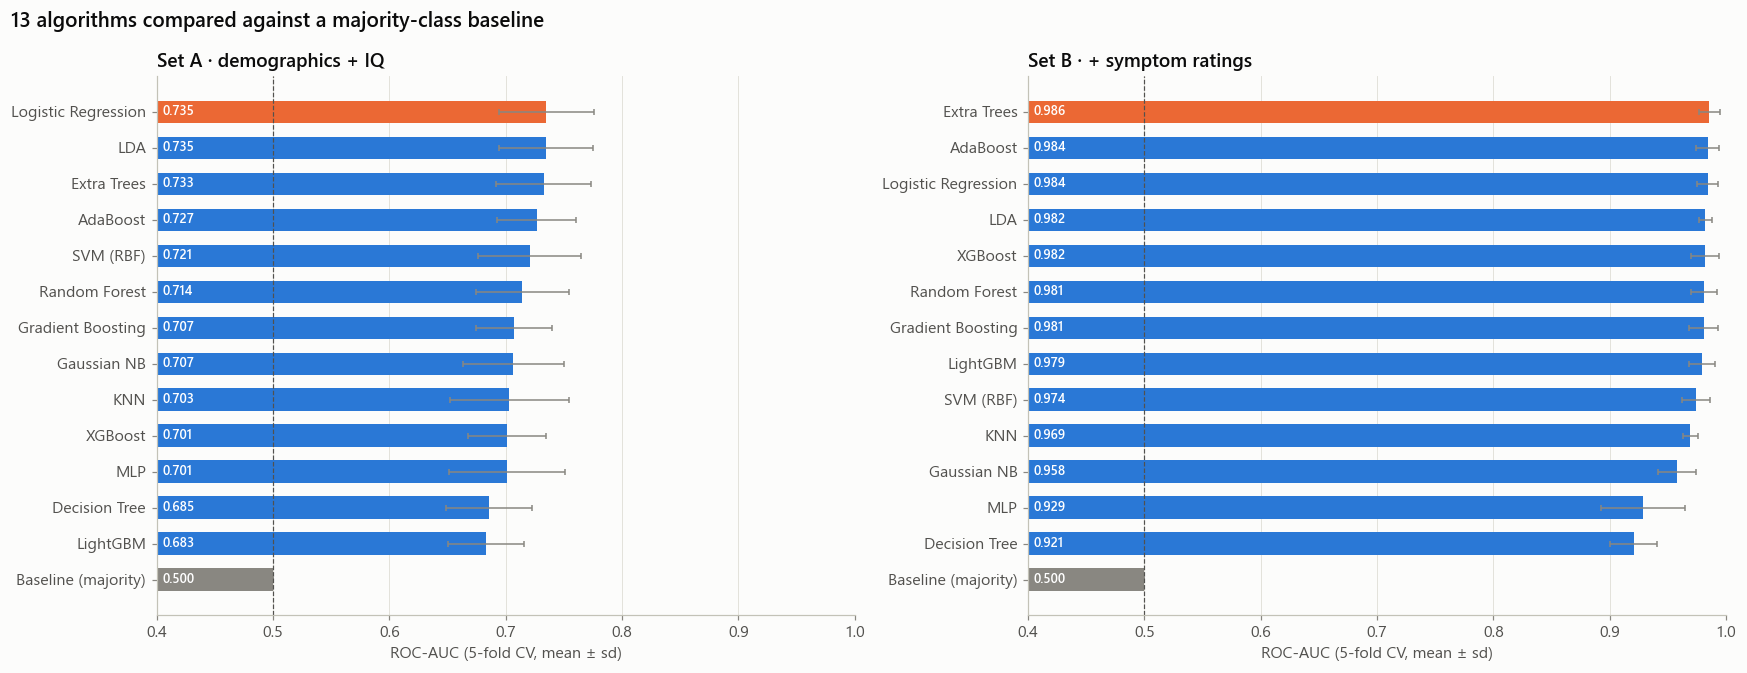

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), sharey=False)
for ax, s, title in [(axes[0], "A_demographic_cognitive", "Set A · demographics + IQ"),
                     (axes[1], "B_with_symptom_ratings", "Set B · + symptom ratings")]:
    r = cv_df[cv_df.set == s].sort_values("roc_auc")
    colors = [MUTED if m.startswith("Baseline") else PALETTE[0] for m in r.model]
    colors[-1] = ADHD_COLOR
    ax.barh(r.model, r.roc_auc, xerr=r.roc_auc_sd, color=colors, height=0.62, error_kw={"ecolor": MUTED, "lw": 1, "capsize": 2})
    for i, v in enumerate(r.roc_auc):
        ax.text(0.405, i, f"{v:.3f}", va="center", ha="left", color="white", fontsize=8.5, fontweight="semibold")
    ax.axvline(0.5, color=INK_2, lw=0.8, ls="--")
    ax.set_xlim(0.4, 1.0); ax.set_xlabel("ROC-AUC (5-fold CV, mean ± sd)"); ax.grid(axis="y", visible=False)
    ax.set_title(title)
fig.suptitle("13 algorithms compared against a majority-class baseline", x=0.01, ha="left", fontsize=13.5, fontweight="semibold")
fig.tight_layout(); savefig(fig, "04_model_comparison_cv"); plt.show()

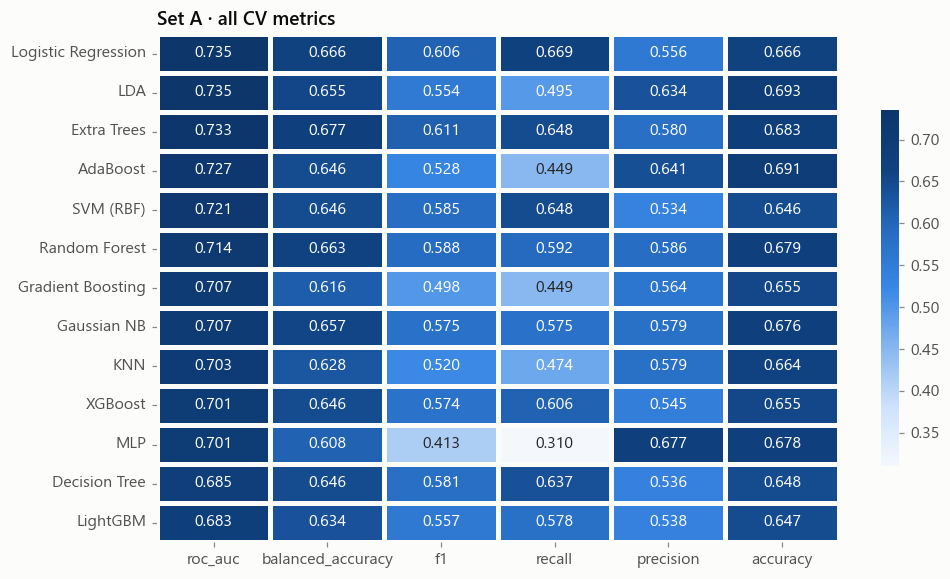

In [4]:
heat = cv_df[(cv_df.set == "A_demographic_cognitive") & ~cv_df.model.str.startswith("Baseline")].set_index("model")[
    ["roc_auc", "balanced_accuracy", "f1", "recall", "precision", "accuracy"]].sort_values("roc_auc", ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(heat, annot=True, fmt=".3f", cmap=SEQ_BLUE, linewidths=2, linecolor=SURFACE, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_ylabel(""); ax.set_title("Set A · all CV metrics"); ax.grid(False)
savefig(fig, "04_metric_heatmap_setA"); plt.show()

## 3. Hyper-parameter tuning
`RandomizedSearchCV` (40 candidates × 5 folds, optimising ROC-AUC) for four model families with different inductive biases.

In [5]:
spaces = {
    "Logistic Regression": (LogisticRegression(max_iter=5000, class_weight="balanced", solver="saga"),
                            {"clf__C": loguniform(1e-3, 1e2), "clf__l1_ratio": uniform(0, 1), "clf__penalty": ["elasticnet"]}),
    "SVM (RBF)": (SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE),
                  {"clf__C": loguniform(1e-2, 1e2), "clf__gamma": loguniform(1e-4, 1)}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
                      {"clf__n_estimators": randint(200, 800), "clf__max_depth": [3, 5, 8, 12, None],
                       "clf__min_samples_leaf": randint(1, 20), "clf__max_features": ["sqrt", "log2", 0.5, 0.8]}),
    "XGBoost": (XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
                {"clf__n_estimators": randint(100, 600), "clf__max_depth": randint(2, 6), "clf__learning_rate": loguniform(0.01, 0.2),
                 "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.5, 0.5), "clf__min_child_weight": randint(1, 10),
                 "clf__reg_lambda": loguniform(0.1, 10), "clf__scale_pos_weight": uniform(1.0, 1.0)}),
}

tuned, tune_rows = {}, []
for set_name in FEATURE_SETS:
    _, X, y = get_xy(set_name, "train")
    for name, (clf, space) in spaces.items():
        search = RandomizedSearchCV(pipe_for(set_name, clf), space, n_iter=40, cv=CV, scoring="roc_auc",
                                    n_jobs=-1, random_state=RANDOM_STATE, refit=True).fit(X, y)
        tuned[(set_name, name)] = search.best_estimator_
        default_auc = cv_df[(cv_df.set == set_name) & (cv_df.model == name)].roc_auc.iloc[0]
        tune_rows.append({"set": set_name, "model": name, "default_auc": default_auc, "tuned_auc": search.best_score_,
                          "best_params": {k.replace("clf__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()}})
tune_df = pd.DataFrame(tune_rows)
tune_df["gain"] = tune_df.tuned_auc - tune_df.default_auc
pd.set_option("display.max_colwidth", 120)
tune_df.round(4)

,set,model,default_auc,tuned_auc,best_params,gain
0,A_demographic_cognitive,Logistic Regression,0.7349,0.7400,"{'C': 0.0746, 'l1_ratio': 0.9507, 'penalty': 'elasticnet'}",0.0051
1,A_demographic_cognitive,SVM (RBF),0.7207,0.7356,"{'C': 20.6514, 'gamma': 0.0027}",0.0150
2,A_demographic_cognitive,Random Forest,0.7142,0.7426,"{'max_depth': 3, 'max_features': 0.8, 'min_samples_leaf': 18, 'n_estimators': 587}",0.0284
3,A_demographic_cognitive,XGBoost,0.7010,0.7422,"{'colsample_bytree': 0.7426, 'learning_rate': 0.0305, 'max_depth': 3, 'min_child_weight': 6, 'n_estimators': 157, 'r...",0.0412
4,B_with_symptom_ratings,Logistic Regression,0.9842,0.9873,"{'C': 0.1907, 'l1_ratio': 0.7852, 'penalty': 'elasticnet'}",0.0031
5,B_with_symptom_ratings,SVM (RBF),0.9740,0.9845,"{'C': 5.4567, 'gamma': 0.0058}",0.0105
6,B_with_symptom_ratings,Random Forest,0.9814,0.9831,"{'max_depth': 5, 'max_features': 0.8, 'min_samples_leaf': 14, 'n_estimators': 441}",0.0017
7,B_with_symptom_ratings,XGBoost,0.9821,0.9832,"{'colsample_bytree': 0.5875, 'learning_rate': 0.1896, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 101, 'r...",0.0011


## 4. Ensembles

In [6]:
ens_rows = []
for set_name in FEATURE_SETS:
    _, X, y = get_xy(set_name, "train")
    members = [(n.split()[0].lower(), tuned[(set_name, n)]) for n in spaces]
    voting = VotingClassifier(members, voting="soft", n_jobs=-1)
    stacking = StackingClassifier(members, final_estimator=LogisticRegression(max_iter=2000), cv=5, n_jobs=-1)
    for name, est in [("Soft Voting", voting), ("Stacking", stacking)]:
        res = cross_validate(est, X, y, cv=CV, scoring="roc_auc", n_jobs=-1)
        tuned[(set_name, name)] = est
        ens_rows.append({"set": set_name, "model": name, "tuned_auc": res["test_score"].mean()})
leader = pd.concat([tune_df[["set", "model", "tuned_auc"]], pd.DataFrame(ens_rows)]).sort_values(["set", "tuned_auc"], ascending=[True, False])
leader.round(4).reset_index(drop=True)

,set,model,tuned_auc
0,A_demographic_cognitive,Random Forest,0.7426
1,A_demographic_cognitive,Soft Voting,0.7423
2,A_demographic_cognitive,XGBoost,0.7422
3,A_demographic_cognitive,Logistic Regression,0.7400
4,A_demographic_cognitive,SVM (RBF),0.7356
5,A_demographic_cognitive,Stacking,0.6701
6,B_with_symptom_ratings,Logistic Regression,0.9873
7,B_with_symptom_ratings,Soft Voting,0.9866
8,B_with_symptom_ratings,Stacking,0.9864
9,B_with_symptom_ratings,SVM (RBF),0.9845


In [7]:
best = {s: leader[leader.set == s].iloc[0].model for s in FEATURE_SETS}
print("Selected final model per feature set (highest CV ROC-AUC):", best)

Selected final model per feature set (highest CV ROC-AUC): {'A_demographic_cognitive': 'Random Forest', 'B_with_symptom_ratings': 'Logistic Regression'}


## 5. Threshold selection (training data only)
The default 0.5 cut-off is arbitrary. We pick the threshold that maximises **Youden's J** (sensitivity + specificity − 1) on *out-of-fold* predictions of the training set, then freeze it before touching the test set.

In [8]:
thresholds, oof = {}, {}
for s in FEATURE_SETS:
    _, X, y = get_xy(s, "train")
    p = cross_val_predict(clone(tuned[(s, best[s])]), X, y, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
    fpr, tpr, thr = roc_curve(y, p)
    thresholds[s] = float(thr[np.argmax(tpr - fpr)]); oof[s] = (y, p)
    print(f"{s}: Youden-optimal threshold = {thresholds[s]:.3f}")

A_demographic_cognitive: Youden-optimal threshold = 0.496
B_with_symptom_ratings: Youden-optimal threshold = 0.394


## 6. Final evaluation on the locked test set

In [9]:
def bootstrap_ci(y, p, fn, n=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        vals.append(fn(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])

final, test_preds = {}, {}
for s in FEATURE_SETS:
    _, X, y = get_xy(s, "train"); dt, Xt, yt = get_xy(s, "test")
    model = clone(tuned[(s, best[s])]).fit(X, y)
    pt = model.predict_proba(Xt)[:, 1]; yhat = (pt >= thresholds[s]).astype(int)
    tn, fp, fn_, tp = confusion_matrix(yt, yhat).ravel()
    lo, hi = bootstrap_ci(yt, pt, roc_auc_score)
    final[s] = {"model": best[s], "threshold": thresholds[s], "n_test": int(len(yt)),
                "roc_auc": roc_auc_score(yt, pt), "roc_auc_ci95": [float(lo), float(hi)],
                "pr_auc": average_precision_score(yt, pt), "accuracy": accuracy_score(yt, yhat),
                "balanced_accuracy": balanced_accuracy_score(yt, yhat), "f1": f1_score(yt, yhat),
                "sensitivity": tp / (tp + fn_), "specificity": tn / (tn + fp), "precision": precision_score(yt, yhat),
                "npv": tn / (tn + fn_), "brier": brier_score_loss(yt, pt), "confusion": [[int(tn), int(fp)], [int(fn_), int(tp)]]}
    test_preds[s] = (yt, pt, yhat, dt)
    joblib.dump(model, MODELS / f"best_model_{s}.joblib")
    print(f"\n===== {s} · {best[s]} =====")
    print(classification_report(yt, yhat, target_names=["TD", "ADHD"], digits=3))

pd.DataFrame(final).T.drop(columns=["confusion"]).round(3)


===== A_demographic_cognitive · Random Forest =====
              precision    recall  f1-score   support

          TD      0.743     0.652     0.694       115
        ADHD      0.535     0.639     0.582        72

    accuracy                          0.647       187
   macro avg      0.639     0.646     0.638       187
weighted avg      0.663     0.647     0.651       187




===== B_with_symptom_ratings · Logistic Regression =====
              precision    recall  f1-score   support

          TD      0.930     0.833     0.879        48
        ADHD      0.855     0.940     0.895        50

    accuracy                          0.888        98
   macro avg      0.892     0.887     0.887        98
weighted avg      0.892     0.888     0.887        98



,model,threshold,n_test,roc_auc,roc_auc_ci95,pr_auc,accuracy,balanced_accuracy,f1,sensitivity,specificity,precision,npv,brier
A_demographic_cognitive,Random Forest,0.495962,187,0.728684,"[0.6543978391693784, 0.8001765254407618]",0.657174,0.647059,0.645531,0.582278,0.638889,0.652174,0.534884,0.742574,0.208808
B_with_symptom_ratings,Logistic Regression,0.394373,98,0.955,"[0.9064897946332287, 0.9875100385899039]",0.948001,0.887755,0.886667,0.895238,0.94,0.833333,0.854545,0.930233,0.077616


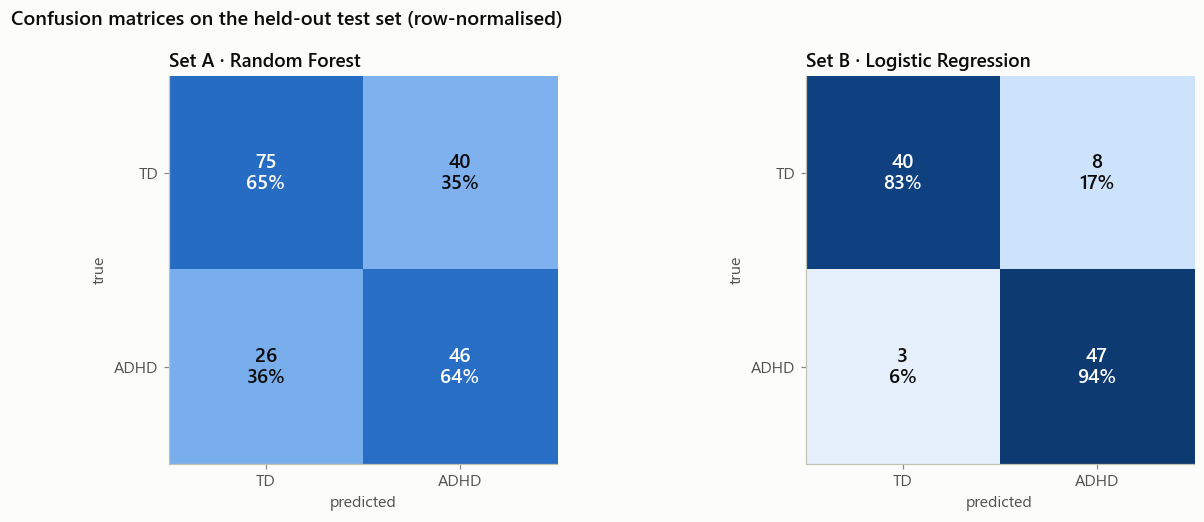

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, s, title in [(axes[0], "A_demographic_cognitive", "Set A"), (axes[1], "B_with_symptom_ratings", "Set B")]:
    cm = np.array(final[s]["confusion"]); pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap=SEQ_BLUE, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n{pct[i, j]:.0%}", ha="center", va="center", fontsize=13,
                    color="white" if pct[i, j] > 0.55 else INK, fontweight="semibold")
    ax.set_xticks([0, 1], ["TD", "ADHD"]); ax.set_yticks([0, 1], ["TD", "ADHD"]); ax.grid(False)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{title} · {final[s]['model']}")
fig.suptitle("Confusion matrices on the held-out test set (row-normalised)", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout(); savefig(fig, "04_confusion_matrices"); plt.show()

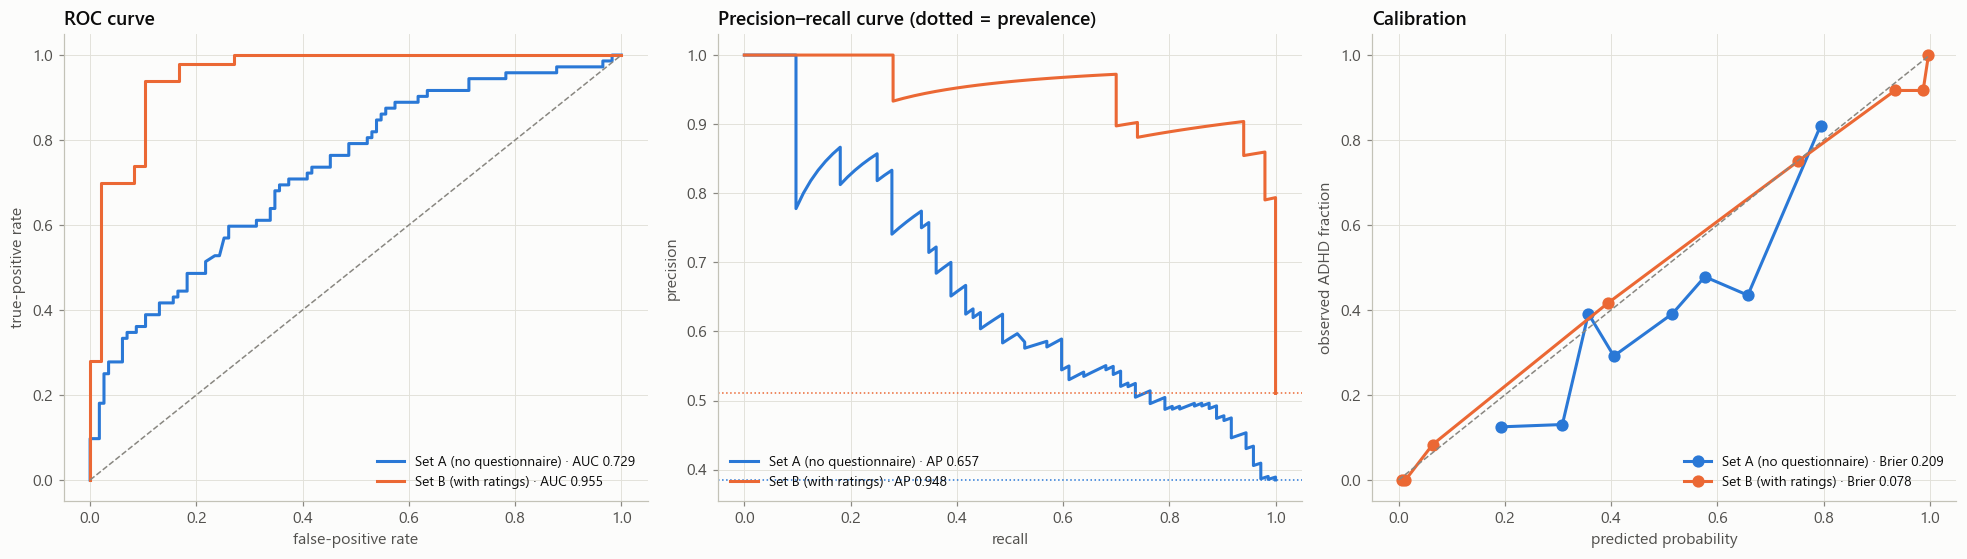

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
labels = {"A_demographic_cognitive": "Set A (no questionnaire)", "B_with_symptom_ratings": "Set B (with ratings)"}
for (s, (yt, pt, yhat, _)), c in zip(test_preds.items(), [PALETTE[0], PALETTE[1]]):
    fpr, tpr, _ = roc_curve(yt, pt)
    axes[0].plot(fpr, tpr, color=c, label=f"{labels[s]} · AUC {final[s]['roc_auc']:.3f}")
    prec, rec, _ = precision_recall_curve(yt, pt)
    axes[1].plot(rec, prec, color=c, label=f"{labels[s]} · AP {final[s]['pr_auc']:.3f}")
    axes[1].axhline(yt.mean(), color=c, lw=1, ls=":")
    frac, mean_pred = calibration_curve(yt, pt, n_bins=8, strategy="quantile")
    axes[2].plot(mean_pred, frac, color=c, marker="o", ms=7, label=f"{labels[s]} · Brier {final[s]['brier']:.3f}")
axes[0].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1); axes[0].set(xlabel="false-positive rate", ylabel="true-positive rate", title="ROC curve")
axes[1].set(xlabel="recall", ylabel="precision", title="Precision–recall curve (dotted = prevalence)")
axes[2].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1); axes[2].set(xlabel="predicted probability", ylabel="observed ADHD fraction", title="Calibration")
for ax in axes: ax.legend(loc="lower right" if ax is not axes[1] else "lower left", fontsize=9)
fig.tight_layout(); savefig(fig, "04_roc_pr_calibration"); plt.show()

## 7. Robustness checks
### 7a. Leave-one-site-out (Set A)
Train on 8 sites, test on the unseen 9th. This is the honest estimate of how the model would do in a **new clinic**.

In [12]:
dA = df.copy(); fsA = FEATURE_SETS["A_demographic_cognitive"]
XA_all, yA_all, groups = dA[fsA["numeric"]], dA["adhd"].values, dA["site"].values
logo_rows = []
for tr, te in LeaveOneGroupOut().split(XA_all, yA_all, groups):
    m = clone(tuned[("A_demographic_cognitive", best["A_demographic_cognitive"])]).fit(XA_all.iloc[tr], yA_all[tr])
    p = m.predict_proba(XA_all.iloc[te])[:, 1]; yh = (p >= thresholds["A_demographic_cognitive"]).astype(int)
    yt = yA_all[te]
    logo_rows.append({"held_out_site": groups[te][0], "n": len(te), "adhd_rate": yt.mean(),
                      "roc_auc": roc_auc_score(yt, p) if len(np.unique(yt)) > 1 else np.nan,
                      "accuracy": accuracy_score(yt, yh), "balanced_accuracy": balanced_accuracy_score(yt, yh) if len(np.unique(yt)) > 1 else np.nan})
logo = pd.DataFrame(logo_rows).sort_values("roc_auc", ascending=False)
logo.round(3)

,held_out_site,n,adhd_rate,roc_auc,accuracy,balanced_accuracy
4,Peking_1,136,0.353,0.860,0.816,0.801
2,NeuroIMAGE,73,0.493,0.785,0.507,0.500
7,Pittsburgh,98,0.041,0.763,0.582,0.662
6,Peking_3,42,0.452,0.728,0.619,0.638
5,Peking_2,67,0.522,0.704,0.687,0.688
3,OHSU,113,0.381,0.698,0.681,0.617
1,NYU,263,0.578,0.680,0.624,0.616
0,KKI,83,0.265,0.565,0.566,0.574
8,WashU,60,0.000,NaN,0.783,NaN


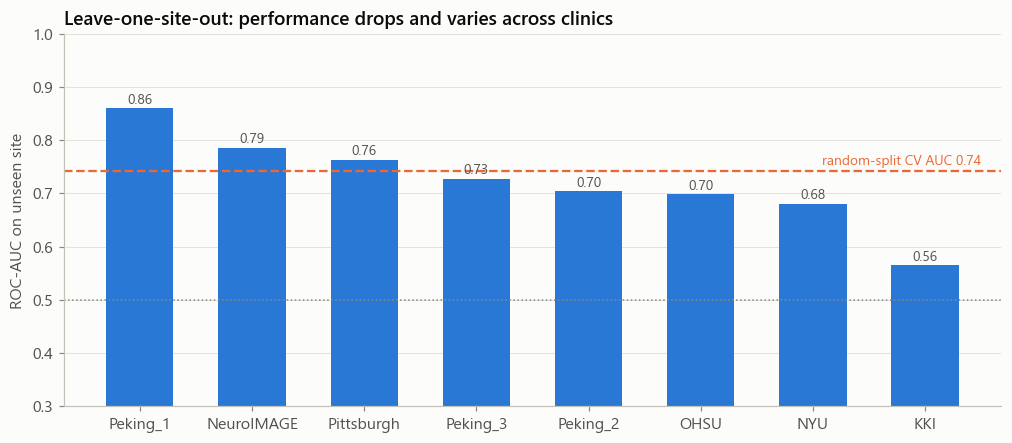

WashU has no ADHD cases, so AUC is undefined; accuracy there = 0.783


In [13]:
fig, ax = plt.subplots(figsize=(11, 4.4))
l = logo.dropna(subset=["roc_auc"])
ax.bar(l.held_out_site, l.roc_auc, color=PALETTE[0], width=0.6)
for i, v in enumerate(l.roc_auc): ax.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=9, color=INK_2)
cv_auc_A = leader[leader.set == "A_demographic_cognitive"].tuned_auc.iloc[0]
ax.axhline(cv_auc_A, color=ADHD_COLOR, lw=1.5, ls="--"); ax.text(len(l) - 0.5, cv_auc_A + 0.012, f"random-split CV AUC {cv_auc_A:.2f}", ha="right", color=ADHD_COLOR, fontsize=9)
ax.axhline(0.5, color=MUTED, lw=1, ls=":"); ax.set_ylim(0.3, 1); ax.set_ylabel("ROC-AUC on unseen site"); ax.grid(axis="x", visible=False)
ax.set_title("Leave-one-site-out: performance drops and varies across clinics")
savefig(fig, "04_leave_one_site_out"); plt.show()
print("WashU has no ADHD cases, so AUC is undefined; accuracy there =", round(logo[logo.held_out_site == "WashU"].accuracy.iloc[0], 3))

### 7b. The site confound, quantified
What if we *did* give the model the site name?

In [14]:
_, X, y = get_xy("A_demographic_cognitive", "train")
Xs = df[df.split == "train"][fsA["numeric"] + ["site"]]
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
no_site = cross_validate(Pipeline([("prep", make_preprocessor(fsA["numeric"], [])), ("clf", lr)]), X, y, cv=CV, scoring="roc_auc")["test_score"].mean()
with_site = cross_validate(Pipeline([("prep", make_preprocessor(fsA["numeric"], ["site"])), ("clf", lr)]), Xs, y, cv=CV, scoring="roc_auc")["test_score"].mean()
only_site = cross_validate(Pipeline([("prep", make_preprocessor([], ["site"])), ("clf", lr)]), Xs[["site"]], y, cv=CV, scoring="roc_auc")["test_score"].mean()
confound = {"without_site": no_site, "with_site": with_site, "site_only": only_site}
pd.Series(confound, name="CV ROC-AUC").round(3)

without_site    0.735
with_site       0.803
site_only       0.703
Name: CV ROC-AUC, dtype: float64

**The site name on its own** predicts diagnosis well above chance, and adding it inflates the score. A model trained like that would look better on paper but would not transfer to a new clinic, which is why `site` was excluded.

### 7c. Subgroup performance (sex)

In [15]:
sub_rows = []
for s in FEATURE_SETS:
    yt, pt, yhat, dt = test_preds[s]
    for sex, lab in [(1, "boys"), (0, "girls")]:
        m = (dt.sex_male == sex).values
        if m.sum() and len(np.unique(yt[m])) > 1:
            sub_rows.append({"set": s, "group": lab, "n": int(m.sum()), "adhd_rate": yt[m].mean(), "roc_auc": roc_auc_score(yt[m], pt[m]),
                             "sensitivity": recall_score(yt[m], yhat[m]), "specificity": recall_score(1 - yt[m], 1 - yhat[m])})
subgroups = pd.DataFrame(sub_rows)
subgroups.round(3)

,set,group,n,adhd_rate,roc_auc,sensitivity,specificity
0,A_demographic_cognitive,boys,111,0.505,0.655,0.750,0.345
1,A_demographic_cognitive,girls,76,0.211,0.661,0.250,0.933
2,B_with_symptom_ratings,boys,58,0.655,0.920,0.921,0.750
3,B_with_symptom_ratings,girls,40,0.300,0.988,1.000,0.893


Sensitivity for girls is the number to watch: because boys dominate the ADHD class, models lean on sex as a cue and can **under-detect ADHD in girls**, mirroring a known real-world bias in diagnosis.

## 8. Secondary task: subtype classification (TD vs ADHD-Combined vs ADHD-Inattentive), Set B

              precision    recall  f1-score   support

      ADHD-C      0.556     0.625     0.588        24
      ADHD-I      0.577     0.577     0.577        26
          TD      0.933     0.875     0.903        48

    accuracy                          0.735        98
   macro avg      0.689     0.692     0.689        98
weighted avg      0.746     0.735     0.740        98



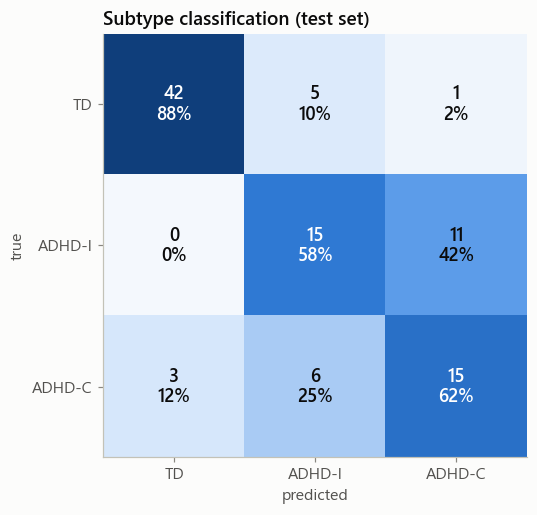

In [16]:
fsB = FEATURE_SETS["B_with_symptom_ratings"]
dm = df[df.rating_scale.notna() & df.dx_label.isin(["TD", "ADHD-C", "ADHD-I"])]
trm, tem = dm[dm.split == "train"], dm[dm.split == "test"]
multi = Pipeline([("prep", make_preprocessor(fsB["numeric"], [])),
                  ("clf", LogisticRegression(max_iter=5000, class_weight="balanced", C=1.0))])
multi.fit(trm[fsB["numeric"]], trm.dx_label)
pm = multi.predict(tem[fsB["numeric"]])
print(classification_report(tem.dx_label, pm, digits=3))
labs = ["TD", "ADHD-I", "ADHD-C"]
cm = confusion_matrix(tem.dx_label, pm, labels=labs); pct = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(pct, cmap=SEQ_BLUE, vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]}\n{pct[i, j]:.0%}", ha="center", va="center", color="white" if pct[i, j] > 0.55 else INK, fontsize=12, fontweight="semibold")
ax.set_xticks(range(3), labs); ax.set_yticks(range(3), labs); ax.grid(False); ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Subtype classification (test set)")
savefig(fig, "04_subtype_confusion"); plt.show()
subtype_metrics = {"accuracy": accuracy_score(tem.dx_label, pm), "macro_f1": f1_score(tem.dx_label, pm, average="macro"), "n_test": int(len(tem))}

## 9. Save artefacts

In [17]:
def to_py(o):
    if isinstance(o, dict): return {k: to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    return o

results = to_py({
    "cv_comparison": cv_df[["set", "model", "roc_auc", "roc_auc_sd", "balanced_accuracy", "f1", "recall", "precision", "accuracy"]].round(4).to_dict(orient="records"),
    "tuning": tune_df.assign(best_params=tune_df.best_params.astype(str)).round(4).to_dict(orient="records"),
    "leaderboard": leader.round(4).to_dict(orient="records"),
    "test": {s: {k: (round(v, 4) if isinstance(v, float) else v) for k, v in final[s].items()} for s in final},
    "leave_one_site_out": logo.round(4).replace({np.nan: None}).to_dict(orient="records"),
    "site_confound": {k: round(v, 4) for k, v in confound.items()},
    "subgroups": subgroups.round(4).to_dict(orient="records"),
    "subtype": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in subtype_metrics.items()},
})
(REPORTS / "model_results.json").write_text(json.dumps(results, indent=2))
(WEBSITE_DATA / "model_results.json").write_text(json.dumps(results, indent=2))

# Transparent logistic-regression models exported for the website's interactive demo
demo = {}
for s in FEATURE_SETS:
    _, X, y = get_xy(s, "train")
    fs = FEATURE_SETS[s]
    lr = Pipeline([("prep", make_preprocessor(fs["numeric"], [])),
                   ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0))]).fit(X, y)
    num = lr.named_steps["prep"].named_transformers_["num"]
    p = cross_val_predict(clone(lr), X, y, cv=CV, method="predict_proba")[:, 1]
    fpr, tpr, thr = roc_curve(y, p)
    demo[s] = {"features": fs["numeric"], "medians": num.named_steps["impute"].statistics_.round(5).tolist(),
               "means": num.named_steps["scale"].mean_.round(5).tolist(), "scales": num.named_steps["scale"].scale_.round(5).tolist(),
               "coef": lr.named_steps["clf"].coef_[0].round(5).tolist(), "intercept": float(lr.named_steps["clf"].intercept_[0]),
               "threshold": float(thr[np.argmax(tpr - fpr)]), "cv_auc": float(roc_auc_score(y, p))}
(WEBSITE_DATA / "demo_model.json").write_text(json.dumps(demo, indent=2))
print(json.dumps(results["test"], indent=1)[:1500])

{
 "A_demographic_cognitive": {
  "model": "Random Forest",
  "threshold": 0.496,
  "n_test": 187,
  "roc_auc": 0.7287,
  "roc_auc_ci95": [
   0.6543978391693784,
   0.8001765254407618
  ],
  "pr_auc": 0.6572,
  "accuracy": 0.6471,
  "balanced_accuracy": 0.6455,
  "f1": 0.5823,
  "sensitivity": 0.6389,
  "specificity": 0.6522,
  "precision": 0.5349,
  "npv": 0.7426,
  "brier": 0.2088,
  "confusion": [
   [
    75,
    40
   ],
   [
    26,
    46
   ]
  ]
 },
 "B_with_symptom_ratings": {
  "model": "Logistic Regression",
  "threshold": 0.3944,
  "n_test": 98,
  "roc_auc": 0.955,
  "roc_auc_ci95": [
   0.9064897946332287,
   0.9875100385899039
  ],
  "pr_auc": 0.948,
  "accuracy": 0.8878,
  "balanced_accuracy": 0.8867,
  "f1": 0.8952,
  "sensitivity": 0.94,
  "specificity": 0.8333,
  "precision": 0.8545,
  "npv": 0.9302,
  "brier": 0.0776,
  "confusion": [
   [
    40,
    8
   ],
   [
    3,
    47
   ]
  ]
 }
}


## Summary
- **Set A (no questionnaire):** see test metrics above. Demographics and IQ carry a modest but real signal (AUC well above 0.5), far from clinically useful on their own.
- **Set B (with symptom ratings):** near-ceiling performance, because the ratings are part of how the diagnosis is made. This is a screening tool, not an objective biomarker.
- **Generalisation:** leave-one-site-out scores are lower and vary by clinic; the site name alone predicts diagnosis, so it must never be a feature.
- **Fairness:** check sensitivity in girls before any real-world use.

**Next:** `05_model_interpretation.ipynb` (why the models decide what they decide)